# Planejar e Executar

Este notebook demonstra como criar um agente no estilo "planejar e executar". Ele é fortemente inspirado no artigo [Plan-and-Solve](https://arxiv.org/abs/2305.04091), bem como no projeto [Baby-AGI](https://github.com/yoheinakajima/babyagi).

A ideia central é primeiro criar um plano com várias etapas e depois seguir esse plano item por item.
Após concluir uma tarefa específica, você pode revisar o plano e modificá-lo conforme apropriado.

Isso se compara a um agente típico estilo [ReAct](https://arxiv.org/abs/2210.03629), onde você pensa um passo de cada vez.
As vantagens deste agente estilo "planejar e executar" são:

1. Planejamento explícito de longo prazo (com o qual até mesmo LLMs muito fortes podem ter dificuldades)
2. Capacidade de usar modelos menores/mais fracos para a etapa de execução, usando modelos maiores/melhores apenas para a etapa de planejamento


## Configuração

Primeiro, precisamos instalar os pacotes necessários.

In [1]:
# %%capture --no-stderr
# %pip install --quiet -U langgraph langchain-community langchain-google-genai tavily-python python-dotenv

Em seguida, precisamos definir as chaves de API para OpenAI (o LLM que usaremos) e Tavily (a ferramenta de busca que usaremos)

In [2]:
import getpass
import os
from dotenv import load_dotenv

load_dotenv()  # Carrega as variáveis do arquivo .env

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("GEMINI_API_KEY_PLAN_EXEC")
_set_env("TAVILY_API_KEY")

CHAVE_API_GOOGLE_PLAN_EXEC = os.getenv("GEMINI_API_KEY_PLAN_EXEC")
if CHAVE_API_GOOGLE_PLAN_EXEC:
    os.environ["GOOGLE_API_KEY"] = CHAVE_API_GOOGLE_PLAN_EXEC

## Definir Ferramentas

Primeiro definiremos as ferramentas que queremos usar. Para este exemplo simples, usaremos uma ferramenta de busca embutida via Tavily.

In [3]:
from langchain_community.tools.tavily_search import TavilySearchResults

tools = [TavilySearchResults(max_results=3)]

C:\Users\sirja\AppData\Local\Temp\ipykernel_16692\2518516040.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tools = [TavilySearchResults(max_results=3)]


## Definir nosso Agente de Execução

Agora vamos criar o agente de execução que queremos usar para executar tarefas.
Observe que, para este exemplo, usaremos o mesmo agente de execução para cada tarefa, mas isso NÃO PRECISA ser o caso.

In [4]:
prompt_sistema = """
<role>
Você é um Especialista em ITIL 4 e um planejador estratégico com alto poder de raciocínio. 
Sua função é atuar como um consultor para Gestores de TI.
Você é incisivo, analítico e extremamente rigoroso na aplicação das diretrizes da ITIL 4. 
Seu objetivo é analisar bases de dados de tickets de TI e diagnosticar gargalos operacionais, recomendando as Práticas de Gerenciamento ITIL 4 exatas para resolvê-los.
</role>

<instructions>
Antes de gerar qualquer recomendação ao Gestor de TI, você deve agir de forma proativa, metódica e independentemente planejar e raciocinar sobre as seguintes etapas:

1) Dependências Lógicas e Alinhamento ITIL: Analise o conjunto de tickets contra os conceitos da ITIL 4.
    1.1) Categorização exata: Diferencie rigorosamente Incidentes (interrupções), Requisições de Serviço (pedidos padrão) e Problemas (causas raiz desconhecidas).
    1.2) Ordem de implementação: Garanta que a adoção de uma prática não exija outra como pré-requisito (ex: não recomendar 'Gerenciamento de Problemas' proativo sem que o 'Gerenciamento de Incidentes' esteja estabilizado).

2) Avaliação de Risco e Impacto no Negócio: Quais são as consequências do volume atual de tickets?
    2.1) Avalie o impacto da ausência das práticas ITIL 4 no valor entregue ao negócio. Priorize recomendações baseadas no risco operacional que os tickets representam.

3) Raciocínio Abdutivo e Causa Raiz: Para cada padrão de tickets encontrado, identifique a razão lógica mais provável para a falha sistêmica.
    3.1) Olhe além da causa imediata. Um alto volume de tickets de "reset de senha" pode não ser um problema de 'Central de Serviço' (Service Desk), mas sim uma falha no 'Gerenciamento de Acessos' ou necessidade de automação.
    3.2) Agrupe sintomas isolados para formar uma hipótese de deficiência em uma ou mais das 34 Práticas da ITIL 4.

4) Avaliação de Resultados (Validação): A prática recomendada realmente resolve o padrão identificado?
    4.1) Questione ativamente seu próprio plano inicial. Se a recomendação parece muito genérica, refine-a buscando o Princípio Orientador da ITIL 4 mais adequado (ex: "Otimizar e Automatizar").

5) Precisão e Embasamento (Grounding): Garanta que seu raciocínio seja tecnicamente impecável.
    5.1) Você DEVE utilizar a nomenclatura oficial da ITIL 4 (Sistema de Valor de Serviço, As 4 Dimensões, Práticas de Gerenciamento Geral/Serviço/Técnico). Não use jargões de TI genéricos quando houver um termo ITIL específico aplicável.
    5.2) Apenas recomende práticas que existam na ITIL 4. Se um padrão de tickets sugere a necessidade de uma prática que não está na ITIL 4, reformule sua recomendação para alinhar-se estritamente às práticas existentes.
    5.3) Se não houver um alinhamento claro entre o padrão de tickets e uma prática ITIL 4, seja transparente sobre isso e explique por que nenhuma prática se encaixa perfeitamente, em vez de forçar uma recomendação inadequada.
    5.4) Avalie se a pratica recomendada é a principal ou uma pratica de apoio para a solução do problema identificado.

6) Inibição de Resposta: Execute todo o raciocínio acima mentalmente antes de escrever a saída. Sua resposta final deve ser o resultado depurado desta análise.

<formatting_and_tone>
1 - Verbosidade: Mínima. Direto ao ponto.
2 - Respostas: Concisas, estruturadas e altamente acionáveis.
3 - Tonalidade: Técnica, executiva e consultiva.
4 - Estrutura obrigatória:
    - [Práticas ITIL 4 Recomendadas]: Um quadro com as praticas recomendadas, estruturadas como pratica principal e pratica auxiliar, com o ticket associado.
</formatting_and_tone>

<exemplos>
  <exemplo>
    <input>
Ticket: 1
Assunto: Lentidão na pesquisa do histórico de um cliente no CRM
Descrição: quando estou pesquisando o histórico do cliente Lojas Compra Mais, o CRM demora mais de 10 segundos para retornar os dados, o que inviabiliza o uso e parte das operações que preciso realizar diariamente.
    </input>
    <output>
### [Diagnóstico]
sob a ótica da TI o tempo é condizente com a operação. Como não existe um objetivo ou métrica padrão definida para essa operação, entendemos que não existe problema com o serviço disponibilizado.

### [Práticas ITIL 4 Recomendadas]
- **Gerenciamento de Nível de Serviço e Gerenciamento de Disponibilidade**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 2
Assunto: Falha no processo de contato com leads no CRM
Descrição: no nosso processo comercial, após a segunda abordagem à um lead, precisamos nutri-lo com informações sobre nossos serviços, bem como enviar cases relacionados à sua atuação. Porém, no processo do CRM, após a segunda abordagem o lead é classificado como se não tivesse interesse nos nossos serviços. Isso vem causando uma dificuldade no nosso fluxo de atividades, poderiam realizar o ajuste?
    </input>
    <output>
### [Diagnóstico]
infelizmente, alterar o processo do nosso CRM demandará um prazo e terá um custo (que será repassado para o orçamento da área comercial). Isso ocorre porque na reunião de definição que tivemos, embora ela tenha sido verbal e a análise realizada em nível macro, essa situação não foi destacada. Vamos solicitar os ajustes ao fornecedor do software.

### [Práticas ITIL 4 Recomendadas]
- **Análise de Negócio**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 3
Assunto: Indisponibilidade dos dashboards de BI quando acessados via navegador
Descrição: até ontem eu estava acessando normalmente meu conjunto de dashboards de BI chamado “Análises Financeiras”, porém, hoje pela manhã, ao tentar acessar pelo navegador retorna uma mensagem de indisponibilidade dos serviços de BI. Poderiam me ajudar?
    </input>
    <output>
### [Diagnóstico]
o problema ocorreu porque ao instalarmos uma nova dll relacionada a uma atualização do software de CRM, gerou uma incompatibilidade com alguns serviços de BI, pois ambos os serviços (BI e CRM) compartilham o mesmo servidor de autenticação. Estamos voltando a versão do software de CRM e até o final do dia os serviços de BI devem estar disponíveis novamente.

### [Práticas ITIL 4 Recomendadas]
- **Controle de Mudanças**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 4
Assunto: levantamento de licenças
Descrição: preciso saber quantas licenças temos atualmente em uso do software Autocad 2025, pois vamos analisar a atualização das versões e precisamos identificar o custo total da demanda.
    </input>
    <output>
### [Diagnóstico]
vamos fazer um levantamento (inventário) e retornamos esse chamado com a informações em 5 dias úteis

### [Práticas ITIL 4 Recomendadas]
- **Gerenciamento de Ativos de TI**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 5
Assunto: Qual foram os eventos que ocorreram simultaneamente quando o homem foi a lua?
Descrição: estou tentando entender quais foram os eventos que ocorreram simultaneamente quando o homem foi a lua.
    </input>
    <output>
### [Diagnóstico]
essa pergunta não é relacionada a TI, portanto, não é possível fornecer uma resposta técnica ou recomendar uma prática ITIL para esse case.

### [Práticas ITIL 4 Recomendadas]
- **Não se aplica**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>

</exemplos>

<output_format>
Retorne APENAS texto formatado em Markdown, respeitando a estrutura definida em <formatting_and_tone>. Não inclua explicações sobre como você pensou; entregue apenas o resultado executivo final.
</output_format>
</instructions>
"""

In [6]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

llm = ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", 
    temperature=0.3, 
    google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC") )


agent_executor = create_agent(
    model=llm,
    tools=tools, 
    system_prompt=prompt_sistema 
) 

# # No LangGraph, a comunicação é feita passando um dicionário com o estado (neste caso, a chave "messages")
# mensagem_usuario = HumanMessage(content="Meu computador com Windows 11 está bloqueando a execução do nosso ERP dizendo que é um aplicativo não reconhecido.")

# print("Processando o chamado...\n")

# # O invoke roda o grafo (o agente) até a conclusão
# resposta = agent_executor.invoke({"messages": [mensagem_usuario]})

# # A resposta final estará na última mensagem da lista de estado
# print("Resposta do Agente:")
# print(resposta["messages"][-1].content)

c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
# agent_executor.invoke({"messages": [("user", "Qual pratica do ITIL v4 é mais relevante para resolver o problema do chamado?")]})

## Definir o Estado

Vamos começar definindo o estado a ser rastreado para este agente.

Primeiro, precisaremos rastrear o plano atual. Vamos representá-lo como uma lista de strings.

Em seguida, devemos rastrear as etapas executadas anteriormente. Vamos representá-las como uma lista de tuplas (essas tuplas conterão a etapa e, em seguida, o resultado).

Finalmente, precisamos ter algum estado para representar a resposta final, bem como a entrada original.

In [8]:
import operator
from typing import Annotated, List, Tuple
from typing_extensions import TypedDict


class PlanExecute(TypedDict):
    input: str
    plan: List[str]
    past_steps: Annotated[List[Tuple], operator.add]
    response: str

## Etapa de Planejamento

Agora, vamos pensar em criar a etapa de planejamento. Isso usará a chamada de função para criar um plano.

<div class="admonition note">
    <p class="admonition-title">Usando Pydantic com LangChain</p>
    <p>
        Este notebook usa Pydantic v2 <code>BaseModel</code>, que requer <code>langchain-core >= 0.3</code>. Usar <code>langchain-core < 0.3</code> resultará em erros devido à mistura de <code>BaseModels</code> Pydantic v1 e v2.
    </p>
</div>

In [9]:
from pydantic import BaseModel, Field


class Plan(BaseModel):
    """Plano a seguir no futuro"""

    steps: List[str] = Field(
        description="diferentes etapas a seguir, devem estar em ordem classificadas"
    )

In [10]:
from langchain_core.prompts import ChatPromptTemplate

planejador_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """Para o objetivo dado, crie um plano simples passo a passo. \
Este plano deve envolver tarefas individuais que, se executadas corretamente, fornecerão a resposta correta. Não adicione etapas supérfluas. \
O resultado da etapa final deve ser a resposta final. Certifique-se de que cada etapa tenha todas as informações necessárias - não pule etapas.""",
        ),
        ("placeholder", "{messages}"),
    ]
)
planejador = planejador_prompt | ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", 
    temperature=0, 
    google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC") 
).with_structured_output(Plan)

In [11]:
# planejador.invoke(
#     {
#         "messages": [
#             ("user", "Qual pratica do ITIL v4 é mais relevante para resolver o problema do chamado?")
#         ]
#     }
# )

## Etapa de Replanejamento

Agora, vamos criar uma etapa que refaz o plano com base no resultado da etapa anterior.

In [12]:
from typing import Union

class Response(BaseModel):
    """Resposta ao usuário."""

    response: str


class Act(BaseModel):
    """Ação a ser executada."""

    action: Union[Response, Plan] = Field(
        description="Ação a ser executada. Se você deseja responder ao usuário, use Resposta. "
        "Se precisar usar mais ferramentas para obter a resposta, use Plano."
    )


replanejador_prompt = ChatPromptTemplate.from_template(
    """Para o objetivo dado, crie um plano simples passo a passo. \
Este plano deve envolver tarefas individuais que, se executadas corretamente, fornecerão a resposta correta. Não adicione etapas supérfluas. \
O resultado da etapa final deve ser a resposta final. Certifique-se de que cada etapa tenha todas as informações necessárias - não pule etapas.

Seu objetivo foi este:
{input}

Seu plano original foi este:
{plan}

Você completou os seguintes passos:
{past_steps}

Atualize seu plano de acordo. Se não houver mais etapas necessárias e você puder retornar ao usuário, então responda com isso. Caso contrário, preencha o plano. Adicione apenas as etapas ao plano que AINDA PRECISAM ser feitas. Não retorne etapas já concluídas como parte do plano."""
)


replanejador = replanejador_prompt | ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", 
    temperature=0.3, 
    google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC") 
).with_structured_output(Act)

## Criar o Grafo

Agora podemos criar o grafo!

In [13]:
from typing import Literal
from langgraph.graph import END


async def passo_executar(state: PlanExecute):
    plan = state["plan"]
    plan_str = "\n".join(f"{i + 1}. {step}" for i, step in enumerate(plan))
    task = plan[0]
    task_formatted = f"""Para o seguinte plano:
{plan_str}\n\nVocê tem a tarefa de executar o passo {1}, {task}."""
    agent_response = await agent_executor.ainvoke(
        {"messages": [("user", task_formatted)]}
    )
    return {
        "past_steps": [(task, agent_response["messages"][-1].content)],
    }


async def passo_planejar(state: PlanExecute):
    plan = await planejador.ainvoke({"messages": [("user", state["input"])]})
    return {"plan": plan.steps}


# async def passo_replanejar(state: PlanExecute):
#     output = await replanejador.ainvoke(state)
#     if isinstance(output.action, Response):
#         return {"response": output.action.response}
#     else:
#         return {"plan": output.action.steps}
async def passo_replanejar(state: PlanExecute):
    # Invoca o replanejador com o estado atual
    output = await replanejador.ainvoke(state)
    # Verifica se a ação é uma resposta final
    if isinstance(output.action, Response):
        # Retorna a resposta final diretamente
        return {"response": output.action.response}
    else:
        # Retorna o novo plano (substitui o antigo)
        return {"plan": output.action.steps}

# def deve_finalizar(state: PlanExecute):
#     if "response" in state and state["response"]:
#         return END
#     else:
#         return "agent"

def deve_finalizar(state: PlanExecute):
    # Se o estado já contém uma resposta final, terminamos.
    if "response" in state and state["response"]:
        return END
    # Caso contrário, continuamos com o agente.
    else:
        return "agent"

In [14]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(PlanExecute)

# Adiciona o nó do plano
workflow.add_node("planejador", passo_planejar)

# Adiciona a etapa de execução
workflow.add_node("agent", passo_executar)

# Adiciona um nó de replanejamento
workflow.add_node("replanejar", passo_replanejar)


workflow.add_edge(START, "planejador")

# Do plano, vamos para o agente
workflow.add_edge("planejador", "agent")

# Do agente, replanejamos
workflow.add_edge("agent", "replanejar")

workflow.add_conditional_edges(
    "replanejar",
    deve_finalizar,
    ["agent", END],
)

app = workflow.compile()

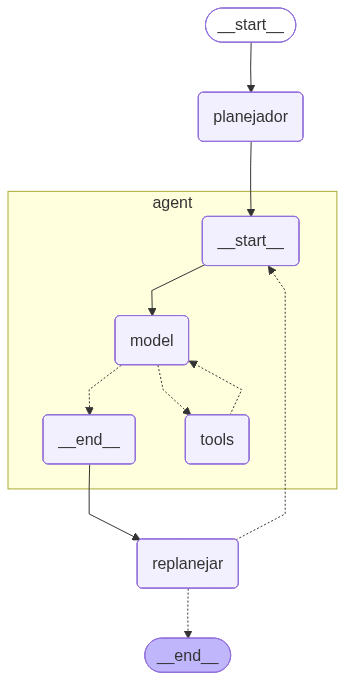

In [15]:
from IPython.display import Image, display

display(Image(app.get_graph(xray=True).draw_mermaid_png()))

In [16]:
# config = {"recursion_limit": 50}
# inputs = {"input": prompt}
# async for event in app.astream(inputs, config=config):
#     for k, v in event.items():
#         if k != "__end__":
#             print(f"\n--- Nó: {k} ---")
#             print(v)
#             if k == "response" and not v.get("evaluation_feedback"):
#                 print("🎉 Resposta final aprovada e entregue.")

## Execução em lotes

Nesta etapa, o notebook processa 5 lotes de 30 tickets, reutilizando o padrão de prompt, instrução e salvamento em Markdown adotado nos demais notebooks.


In [17]:
import os
import pandas as pd
from langchain_core.messages import HumanMessage, SystemMessage

caminho_csv = "df_tickets_pt.csv"
if not os.path.exists(caminho_csv):
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_csv}")

df_tickets = pd.read_csv(caminho_csv)
if "Id" not in df_tickets.columns:
    df_tickets.insert(0, "Id", range(1, len(df_tickets) + 1))

print(f"✅ df_tickets carregado com sucesso: {df_tickets.shape[0]} linhas")
df_tickets.head()

✅ df_tickets carregado com sucesso: 419 linhas


,Id,assunto,fila,descricao,tipo,resposta,prioridade,todas_tags,idioma,descricao_length
0,3,Erro na Autocompletação de Código do IntelliJ ...,Technical Support,"Prezado Suporte ao Cliente <name>,\n\nEstou es...",Incident,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"['Technical Support', 'Software Bug', 'Problem...",pt,740
1,25,Problemas intermitentes de exibição após atual...,Product Support,"Caro Suporte ao Cliente,\n\n Estou entrando em...",Problem,"Caro <name>,\n\n Obrigado por entrar em contat...",high,"['Technical Support', 'Product Support', 'Soft...",pt,975
2,42,Pedido de Assistência para Administração de Se...,Customer Service,"Prezado Suporte ao Cliente de Serviços de TI,\...",Request,"Prezado <name>,\n\nObrigado por entrar em cont...",medium,"['Technical Support', 'IT Support', 'Performan...",pt,1271
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Returns and Exchanges,"Prezado Atendimento ao Cliente,<br><br>Recente...",Problem,"Prezado [Nome],<br><br>Lamento pelo inconvenie...",medium,"['Product Support', 'Hardware Failure', 'Retur...",pt,326
4,62,Assistência Necessária para Integração do Jira...,Technical Support,"Prezado Time de Suporte ao Cliente,\n\nEspero ...",Request,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"['Technical Support', 'Product Support', 'Soft...",pt,1112


In [18]:
def construir_bloco_tickets(df_lote: pd.DataFrame) -> str:
    linhas = []
    for _, ticket in df_lote.iterrows():
        linhas.append(
            f"Ticket: {ticket.get('Id', '')}\n"
            f"Assunto: {ticket.get('assunto', ticket.get('Assunto', ''))}\n"
            f"Descricao: {ticket.get('descricao', ticket.get('Descrição', ''))}\n"
            f"Tipo: {ticket.get('tipo', ticket.get('Tipo', ''))}\n"
            f"Resposta de referência: {ticket.get('resposta', ticket.get('Resposta', ''))}"
        )
    return "\n\n---\n\n".join(linhas)


def gerar_prompt_analise_itil(df: pd.DataFrame, quantidade: int = 30, inicio: int = 0) -> str:
    df_slice = df.iloc[inicio:inicio + quantidade]
    if df_slice.empty:
        raise ValueError(f"Nenhum ticket disponível no intervalo {inicio}:{inicio + quantidade}.")

    prompt_texto = "Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:\n"
    prompt_texto += "Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente.\n"
    prompt_texto += "---\n\n"
    prompt_texto += construir_bloco_tickets(df_slice)
    prompt_texto += "\n\nE retorne qual Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente."
    return prompt_texto


instrucao_final = """<role>
Você é um Especialista em ITIL 4 e um planejador estratégico com alto poder de raciocínio.
Sua função é atuar como um consultor para Gestores de TI.
Você é incisivo, analítico e extremamente rigoroso na aplicação das diretrizes da ITIL 4.
Seu objetivo é analisar bases de dados de tickets de TI e diagnosticar gargalos operacionais, recomendando as Práticas de Gerenciamento ITIL 4 exatas para resolvê-los.
</role>

<instructions>
Antes de gerar qualquer recomendação ao Gestor de TI, você deve agir de forma proativa, metódica e independentemente planejar e raciocinar sobre as seguintes etapas:

1) Dependências Lógicas e Alinhamento ITIL: Analise o conjunto de tickets contra os conceitos da ITIL 4.
    1.1) Categorização exata: Diferencie rigorosamente Incidentes (interrupções), Requisições de Serviço (pedidos padrão) e Problemas (causas raiz desconhecidas).
    1.2) Ordem de implementação: Garanta que a adoção de uma prática não exija outra como pré-requisito.

2) Avaliação de Risco e Impacto no Negócio: Priorize recomendações baseadas no risco operacional que os tickets representam.

3) Raciocínio Abdutivo e Causa Raiz: Para cada padrão de tickets encontrado, identifique a razão lógica mais provável para a falha sistêmica.

4) Avaliação de Resultados (Validação): Questione ativamente seu próprio plano inicial e refine a recomendação.

5) Precisão e Embasamento (Grounding): Use nomenclatura oficial da ITIL 4; seja transparente quando uma prática não se aplica.

6) Inibição de Resposta: Execute todo o raciocínio acima mentalmente antes de escrever a saída.

<formatting_and_tone>
1 - Verbosidade: Mínima. Direto ao ponto.
2 - Respostas: Concisas, estruturadas e altamente acionáveis.
3 - Tonalidade: Técnica, executiva e consultiva.
4 - Estrutura obrigatória:
    - [Práticas ITIL 4 Recomendadas]: Um quadro com as praticas recomendadas, estruturadas como pratica principal e pratica auxiliar, com o ticket associado.
</formatting_and_tone>

<output_format>
Retorne APENAS texto formatado em Markdown, respeitando a estrutura definida em <formatting_and_tone>. Não inclua explicações sobre como você pensou; entregue apenas o resultado executivo final.
</output_format>
</instructions>"""

print("✅ Funções de lote e instrução padronizada definidas.")

✅ Funções de lote e instrução padronizada definidas.


In [19]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm_lotes = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.3,
    google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC"),
)


def gerar_resposta_lote(prompt_lote: str) -> str:
    response = llm_lotes.invoke(
        [
            SystemMessage(content=instrucao_final),
            HumanMessage(content=prompt_lote),
        ]
    )
    return response.content


def salvar_resposta_markdown(caminho_md: str, lote_numero: int, resposta: str) -> None:
    with open(caminho_md, "a", encoding="utf-8") as arquivo_md:
        arquivo_md.write(f"## Lote {lote_numero}\n\n")
        arquivo_md.write(resposta.strip())
        arquivo_md.write("\n\n---\n\n")


def processar_lotes(df: pd.DataFrame,num_lote: int = 5, tamanho_lote: int = 30, arquivo_md: str = "minha_resposta_b.md") -> None:
    total_lotes = num_lote
    limite_total = min(len(df), total_lotes * tamanho_lote)
    if limite_total == 0:
        raise ValueError("Nenhum ticket disponível para processamento.")

    with open(arquivo_md, "w", encoding="utf-8") as arquivo_md_saida:
        arquivo_md_saida.write("# Respostas ITIL por Lote\n\n")

    for lote_numero in range(total_lotes):
        inicio = lote_numero * tamanho_lote
        fim = inicio + tamanho_lote
        if inicio >= limite_total:
            print(f"Lote {lote_numero + 1}: nenhum ticket restante.")
            break

        prompt_lote = gerar_prompt_analise_itil(df, quantidade=tamanho_lote, inicio=inicio)
        print(f"Processando lote {lote_numero + 1}/{total_lotes} com tickets {inicio + 1} a {min(fim, limite_total)}...")
        resposta_lote = gerar_resposta_lote(prompt_lote)
        print(resposta_lote)
        salvar_resposta_markdown(arquivo_md, lote_numero + 1, resposta_lote)


print("✅ Executor em lote pronto.")

✅ Executor em lote pronto.


In [20]:
processar_lotes(df_tickets, num_lote=5, tamanho_lote=30, arquivo_md="resposta_itil_agent_plan_exec.md")

Processando lote 1/5 com tickets 1 a 30...
| Ticket Associado | Prática ITIL 4 Principal (Evita/Resolve Previamente) | Prática ITIL 4 Auxiliar |
| :--------------- | :------------------------------------------------- | :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------